![Banner](../images/09_10_banner_rs_object_detection.png)


# Object Detection 

This notebook opens the object-detection chapter. It explains how GeoLattice finds individual objects in imagery, either as boxes around trees, pools or buildings, or as fields enclosed by predicted boundaries, and it runs short examples on the data used in the chapter's notebooks.

Five notebooks go from boxes in aerial tiles to field parcels in Bangladesh and the US Corn Belt.

- **Object Detection.** This notebook. Boxes around trees, pools or buildings, and fields enclosed by predicted boundaries, with short examples on the chapter data.
- **Object Detection in Aerial Imagery.** Swimming pools with an HSV and contour baseline, then box geometry, non-maximum suppression, tiling, and a detector trained on annotated tree tiles.
- **Field Boundary Detection in Google Satellite Screenshots (Bangladesh).** Classical edges, FC-DenseNet, Delineate Anything V2 and SAM 2.1 on south-west Bangladesh screenshots, exported as field polygons.
- **Field Edge Detection in WorldView Imagery: RGB versus RGB + NIR.** The Patuakhali WorldView study: classical detectors, a texture random forest and six deep networks, with and without near-infrared.
- **Field Edge Detection in Sentinel-2: Fields of The World versus Delineate Anything.** Those two open models on the US Corn Belt, scored against parcels from the Cropland Data Layer.


## Overview

Image classification answers *what is here?* for a pixel, a segment or a whole chip. Many questions about imagery are about **things** instead: *where are the trees, how many swimming pools, where does one field end and the next begin?* Answering them means finding individual objects, each with a location, an extent and a confidence. This chapter covers the two ways of doing that with GeoLattice:

- **Object detection** draws a box around each object and gives it a class and a score: trees, pools, ships, buildings.
- **Field edge detection** delineates objects that tile the landscape and have no gaps between them, such as agricultural fields. A box is useless there. Instead, the boundary between objects is predicted and the closed regions become the objects.

This notebook is the map of the chapter. It defines the tasks, the geometry and the metrics they share, the model families, and what is different when the images come from above. It lists what `geolattice.rsense.classify.image_classification` and `geolattice.rsense.edge_detectors` offer, and runs small examples on the data used in the chapter's notebooks.


## Core concepts

### Learning objectives

1. Separate object detection, instance segmentation and boundary (edge) detection by their input and output.
2. Compute intersection over union (IoU), apply non-maximum suppression (NMS), and read average precision (AP) and mean average precision (mAP).
3. Explain two-stage, one-stage and anchor-free detectors, and the encoder-decoder networks used for boundaries.
4. Say why overhead imagery needs tiling, scale-aware windows, rotation augmentation and duplicate merging in map units.
5. Turn a boundary score into field instances, and see why the threshold controls over- and under-segmentation.
6. Map every method in the chapter to the GeoLattice function that implements it, and to the notebook that uses it.

### Contents

1. What object detection is
2. Task types: boxes, masks and boundaries
3. Box geometry: IoU and non-maximum suppression
4. Detector architectures
5. Boundary networks for field edges
6. What is different about overhead imagery
7. Evaluating detections and boundaries
8. What GeoLattice offers
9. Hands-on
10. Choosing a method
11. The notebooks in this chapter
12. Summary, exercises and references


## What object detection is

A detector maps an image $I$ to a **set** of detections of unknown size,

$$f(I) = \{(\mathbf{b}_j, c_j, s_j)\}_{j=1}^{N},$$

where $\mathbf{b}_j = (x_0, y_0, x_1, y_1)$ is a bounding box, $c_j$ a class and $s_j \in [0, 1]$ a confidence score. Three properties make detection harder than classification:

- **The number of objects is not known.** One tile may hold no tree and the next one 86. The model must decide how many outputs to return.
- **Localisation and recognition are learnt together.** The loss has a classification term and a box-regression term.
- **Duplicates must be removed.** A detector proposes many overlapping boxes for each object, and only one should survive (see *Box geometry* below).

In remote sensing the box is only an intermediate result. Pixel coordinates are converted to map coordinates with the image's affine transform, so every detection becomes a georeferenced polygon that can be counted per zone, joined to parcels, or tracked through time.


## Task types: boxes, masks and boundaries

| Task | Output | Typical objects | GeoLattice | Notebook |
|---|---|---|---|---|
| Object detection (axis-aligned) | box + class + score | trees, pools, cars, livestock | `build_object_detector`, `detect_objects`, `nms`, `mean_average_precision` | 09_10_01 |
| Oriented object detection | rotated box | ships, aircraft, buildings | `build_object_detector("yolo", weights="yolov8n-obb.pt")`, `obb_to_polygon`, `polygon_iou` | 09_10_01 |
| Instance segmentation | one mask per object | roofs, tree crowns, fields | `build_object_detector("mask_rcnn")`, `instances_from_detector`, `ed.detect_delineate_anything`, `ed.detect_sam2` | 09_10_02 |
| Boundary (edge) detection | boundary probability per pixel | field boundaries, bunds, hedges | `ed.classical_edges`, `ed.build_edge_model`, `ed.predict_boundary_probability`, FTW models | 09_10_02 to 09_10_04 |
| Boundary to instances | one polygon per closed region | agricultural fields | `ed.boundary_to_instances`, `ed.detect_field_edges`, `ed.detect_fields_ftw` | 09_10_02 to 09_10_04 |
| Counting | number of objects per zone | trees per block, pools per suburb | `count_objects` | 09_10_01 |

**Why boundaries for fields?** Fields touch each other and fill the landscape. Neighbouring fields often have the same crop and the same colour, so a pixel classifier would label them all "cropland" with nothing in between. A box detector fits irregular, touching fields badly. The bund, ditch or hedge *between* fields is the visible signal, so the model predicts that line. The fields are then the connected regions it encloses. One gap in a line merges two fields, and that weakness of the approach comes back in every edge notebook.


## Box geometry: IoU and non-maximum suppression

**Intersection over union** measures how well two boxes agree:

$$\mathrm{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|} \in [0, 1].$$

It is 1 for identical boxes and 0 for disjoint ones. It is used twice. During **evaluation**, a detection counts as correct if its IoU with an unmatched true box is above a threshold (0.5 is common). During **inference**, it finds duplicates.

**Non-maximum suppression (NMS)** keeps the highest-scoring box, removes every other box whose IoU with it exceeds a threshold, and repeats with the next box still standing. It is greedy and needs a threshold: too low and two touching trees become one, too high and duplicates survive. `ic.nms` works class by class when labels are given, and `ic.merge_detections` does the same with polygons in map units, which is how duplicates from overlapping tiles are removed (see *What is different about overhead imagery* below).

For **oriented boxes** the same ideas hold with rotated rectangles: `obb_to_polygon` builds them and `polygon_iou` computes their IoU.


## Detector architectures

All modern detectors put a convolutional or transformer **backbone** (ResNet, EfficientNet, CSPDarknet, Swin), usually with a feature pyramid (FPN) for objects of different sizes, in front of a **head** that predicts boxes. Their loss combines a classification term and a localisation term,

$$\mathcal{L} = \mathcal{L}_{\text{cls}} + \lambda\, \mathcal{L}_{\text{box}},$$

with cross-entropy or focal loss for the class and a smooth-L1 or IoU-based loss for the box.

| Family | How it works | Examples | Strengths | GeoLattice `arch` |
|---|---|---|---|---|
| Two-stage | a region proposal network suggests candidate boxes, a second head classifies and refines each | Faster R-CNN, Mask R-CNN | accurate, good for small objects | `"faster_rcnn"`, `"mask_rcnn"` |
| One-stage, anchor-based | dense anchors at every location are classified and regressed in one pass; focal loss down-weights the many easy background anchors | RetinaNet | simpler, fast | `"retinanet"` |
| One-stage, anchor-free | every feature-map location predicts its distances to the four box sides and a "centre-ness" | FCOS | no anchor sizes to tune | `"fcos"` |
| Grid / real-time | a single network predicts boxes on a grid of cells at several scales; oriented-box variants exist | YOLOv5 to v11 (Ultralytics) | very fast, easy to train, OBB support | `"yolo"` |
| Set prediction | a transformer outputs a fixed set of boxes matched one-to-one with the truth; no NMS needed | DETR, RT-DETR | no hand-made post-processing | not wrapped in GeoLattice |

**Mask R-CNN** adds a small mask head to Faster R-CNN and returns a pixel mask for each box, which is instance segmentation. 09_10_01 derives the equations of each family and trains a YOLO detector on the tree tiles.


## Boundary networks for field edges

Boundary detection is semantic segmentation with two very unequal classes. A **boundary** band (1 m wide in 09_10_03) is typically 5 to 15 % of the pixels, and **field interior** is the rest. The network returns, for every pixel, a probability $p(\text{boundary} \mid \text{window around the pixel})$.

| Approach | Idea | GeoLattice | Notebook |
|---|---|---|---|
| Classical edge detectors | brightness gradient magnitude $\sqrt{G_x^2 + G_y^2}$ (Roberts, Sobel, Prewitt), Laplacian of Gaussian, Canny | `ed.classical_edges` | all three edge notebooks |
| Texture random forest | per-pixel classifier on gradients, LBP and GLCM texture | `geolattice.rsense.texture` + scikit-learn | 09_10_03 |
| Encoder-decoder networks | U-Net, SegNet, FC-DenseNet56/67/103, FCN-DKConv6 trained on rasterised boundaries | `ed.build_edge_model`, `ed.rasterize_boundaries`, `ed.tile_pairs`, `ed.dihedral_augment` | 09_10_02, 09_10_03 |
| Pretrained field models | Fields of The World: U-Nets trained on 24 countries, two Sentinel-2 dates, 3 classes (background, field, boundary) | `ed.ftw_models`, `ed.load_ftw_model`, `ed.detect_fields_ftw`, `ed.to_fiboa` | 09_10_04 |
| Field instance segmentation | Delineate Anything (YOLO11 trained on 22 million field masks), SAM 2.1 automatic masks | `ed.detect_delineate_anything`, `ed.detect_sam2` | 09_10_02, 09_10_04 |

Whatever produces the probability, the step to objects is the same. Threshold the probability, optionally thicken the boundary to close small gaps (`dilate_pixels`), and label the connected non-boundary regions (`ed.boundary_to_instances`). `ed.detect_field_edges` then returns those regions as georeferenced polygons with area and perimeter.


## What is different about overhead imagery

Detectors were designed for photographs. Satellite, aerial and drone images break several of their assumptions.

| Photographs | Overhead imagery | Consequence | GeoLattice |
|---|---|---|---|
| objects upright, large, few | seen from above at any rotation, often tiny and densely packed (80+ trees per tile) | rotation and flip augmentation; oriented boxes; small-object windows | `ed.dihedral_augment`, `OverheadAugment`, `obb_to_polygon`, `detection_tiles(scales=...)` |
| 640 px images | scenes of 10⁴ to 10⁵ pixels per side | predict tile by tile with overlap, then merge duplicates in map units | `detection_tiles`, `detect_objects`, `merge_detections`, `ed.predict_boundary_probability` (Hann-blended tiles) |
| object size in pixels is arbitrary | object size in **metres** is known, so pixels per object depend on the ground sample distance (GSD) | resample to a working GSD so the object spans enough pixels (0.25 m in 09_10_02, 0.5 m in 09_10_03) | `rasterio.warp.reproject` |
| RGB | multispectral, sometimes NIR helps | change the input channels | `build_edge_model(in_channels=4)` |
| images are independent | neighbouring tiles share objects | split by spatial blocks or sites, never randomly by tile | `spatial_block_split`, `check_split_isolation` |
| boxes are the result | results must be in map coordinates | keep the transform and CRS; export GeoPackage / fiboa GeoParquet | `detect_objects` (GeoDataFrame), `ed.to_fiboa` |


## Evaluating detections and boundaries

**Detections.** Detections are sorted by score and matched greedily to unmatched true boxes with IoU ≥ $t$. Each is then a true positive (TP) or a false positive (FP); unmatched truths are false negatives (FN). Lowering the score threshold traces a precision-recall curve,

$$P = \frac{TP}{TP + FP}, \qquad R = \frac{TP}{TP + FN},$$

and **average precision** is the area under it, $AP_t = \int_0^1 P(R)\, dR$. mAP averages AP over classes. The usual summaries are:

- **AP@0.50** (PASCAL VOC): lenient about position;
- **AP@0.75**: strict;
- **AP@[.50:.95]** (COCO): the mean over $t = 0.50, 0.55, \dots, 0.95$, which rewards tight boxes.

For counting tasks, also report the count error per tile or zone.

**Boundaries and fields.** Pixel scores and object scores answer different questions, and the chapter uses both:

| Level | Metric | GeoLattice |
|---|---|---|
| boundary pixels | precision, recall and F1 of the boundary class, ROC AUC; optional **positional tolerance** (a predicted boundary within $k$ pixels of a true one counts) | `ed.edge_metrics`, `ed.select_threshold` |
| field objects | each true field matched to the predicted field of largest IoU; share matched at IoU ≥ 0.5, median IoU, over- and under-segmentation | `polygon_iou`, GeoPandas overlay |

**Two rules carry over from image classification.**

- Choose every threshold (score, boundary probability, NMS IoU) on validation data, never on the test data.
- Hold out whole blocks, sites or years. In the capstone 09_13_14, validation tiles cut from the training images overstated the boundary F1 on an unseen site by 0.02 to 0.12, and even a second site in the same country cost the best network 0.08.


## What GeoLattice offers

```python
import geolattice.rsense.classify.image_classification as ic   # object detection (section 6 of the module)
from geolattice.rsense import edge_detectors as ed               # field boundaries and field instances
```

| Step | Object detection (`ic`) | Field edges (`ed`) |
|---|---|---|
| Labels | YOLO / COCO boxes; `rasterize_labels` | `rasterize_boundaries` (outline buffer → boundary raster + labelled mask) |
| Training data | `ChipDataset`, `OverheadAugment` | `tile_pairs`, `dihedral_augment` |
| Models | `build_object_detector`: `faster_rcnn`, `mask_rcnn`, `retinanet`, `fcos`, `yolo` | `build_edge_model` (U-Net, SegNet, FC-DenseNet56/67/103, FCN-DKConv6, plus the `build_segmenter` family), `load_edge_model`, `available_models` |
| Pretrained | Ultralytics weights; torchvision COCO weights | `ftw_models`, `ftw_checkpoint`, `load_ftw_model`, `load_delineate_anything`, `load_sam2` |
| Training | Ultralytics `model.train`, `train_model` | `ic.train_model(task="segmentation")` |
| Large-scene inference | `detection_tiles`, `detect_objects`, `merge_detections` | `predict_boundary_probability`, `predict_ftw`, `ftw_stack` |
| Post-processing | `box_iou`, `nms`, `obb_to_polygon`, `polygon_iou`, `instances_from_detector` | `boundary_to_instances`, `detect_field_edges`, `detect_field_edges_from_raster`, `detect_fields_ftw`, `detect_delineate_anything`, `detect_sam2` |
| Evaluation | `mean_average_precision` (VOC / COCO thresholds, custom IoU) | `edge_metrics` (boundary/field P, R, F1, AUC, tolerance), `select_threshold` |
| Output | `count_objects`, `export_vectors` | `FieldEdgeResult` (fields, boundaries, probability, labels), `to_fiboa` |

The deep-learning parts need `pip install "geolattice[rsense-dl]"`; YOLO and Delineate Anything also need `ultralytics`. Importing the modules does not import PyTorch. No function downloads weights unless asked (`download=True` or a weights URL).


## Hands-on

The examples use data shipped in `data/` for this chapter and run on a CPU in about a minute. Nothing is trained here.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Standard library: silence warnings and build file paths that work on every operating system.
import warnings
from pathlib import Path

# Third-party libraries for vector data, plotting, arrays, tables, rasters, images and geometry.
import geopandas as gpd                    # vector data (field polygons, detections as polygons)
import matplotlib.pyplot as plt            # all figures
import numpy as np                         # arrays of boxes, scores and pixels
import pandas as pd                        # result tables
import rasterio                            # read the WorldView GeoTIFF
from matplotlib.patches import Rectangle   # draw bounding boxes on images
from PIL import Image                      # read JPEG/PNG image tiles
from shapely.geometry import box           # make rectangular polygons from box corners

# GeoLattice: the image-classification module (object detection lives in it) and the field-edge tools.
import geolattice.rsense.classify.image_classification as ic
from geolattice.rsense import edge_detectors as ed

warnings.filterwarnings("ignore")          # keep the output short: hide library warnings
DATA = Path("../../../../Data/08_remote_sensing/08_10_object_detection")                        # chapter data folder, relative to this notebook
print("Tasks          :", ic.TASKS)        # the six task types GeoLattice knows (detection is one of them)
print("Edge networks  :", ed.available_models())   # network names accepted by ed.build_edge_model

Tasks          : ('classification', 'semantic-segmentation', 'detection', 'instance-segmentation', 'change-detection', 'time-series')
Edge networks  : ['FC-DenseNet56', 'FC-DenseNet67', 'FC-DenseNet103', 'SegNet', 'FCN-DKConv6', 'unet', 'unet_basic', 'unetplusplus', 'deeplabv3plus', 'deeplabv3', 'fcn_resnet50', 'fcn_resnet101', 'deeplabv3_resnet50', 'deeplabv3_resnet101', 'deeplabv3_mobilenet', 'lraspp_mobilenet', 'fpn', 'manet', 'pspnet', 'segformer', 'upernet']


### IoU and non-maximum suppression

Four detections: A, B and C are three boxes on one object, as a detector or overlapping tiles would produce, and D is a neighbouring object. Dashed boxes are the truth.


IoU between the four detections:


,A,B,C,D
A,1.00,0.70,0.68,0.0
B,0.70,1.00,0.48,0.0
C,0.68,0.48,1.00,0.0
D,0.00,0.00,0.00,1.0


kept after NMS (IoU threshold 0.5): ['A', 'D']


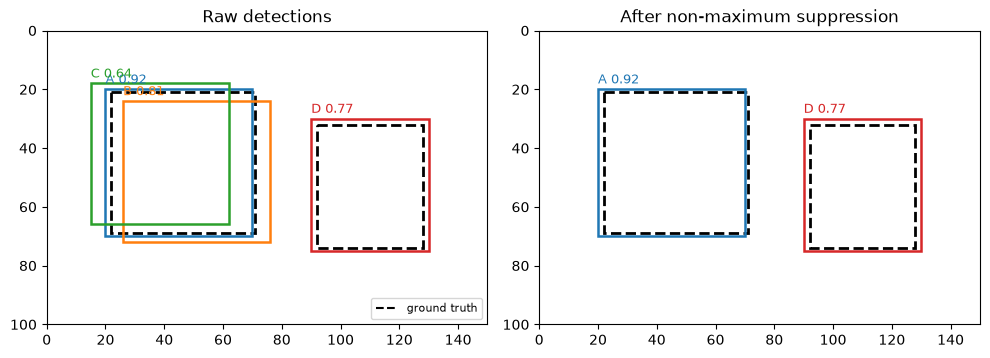

In [2]:
# Three detections of one object (as a detector or overlapping tiles would produce) and one of a neighbour.
# Each box is [x0, y0, x1, y1] in pixels: top-left corner, then bottom-right corner.
boxes = np.array([[20, 20, 70, 70],      # A: the best box
                  [26, 24, 76, 72],      # B: A shifted by a few pixels
                  [15, 18, 62, 66],      # C: A, slightly smaller
                  [90, 30, 130, 75]])    # D: a different object
scores = np.array([0.92, 0.81, 0.64, 0.77])                 # detector confidence of A, B, C and D
truth = np.array([[22, 21, 71, 69], [92, 32, 128, 74]])     # the two true (ground-truth) boxes

print("IoU between the four detections:")
# ic.box_iou returns the IoU of every pair of boxes; show it as a labelled 4 x 4 table.
display(pd.DataFrame(ic.box_iou(boxes, boxes), index=list("ABCD"), columns=list("ABCD")).round(2))
# Non-maximum suppression: keep the best box, drop boxes overlapping it by IoU > 0.5, repeat.
keep = ic.nms(boxes, scores, iou_threshold=0.5)
print("kept after NMS (IoU threshold 0.5):", [ "ABCD"[k] for k in keep])   # indices -> letters

# Two panels: all detections, and the detections kept by NMS.
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, show, title in [(ax[0], range(4), "Raw detections"), (ax[1], keep, "After non-maximum suppression")]:
    for t in truth:                                          # true boxes as dashed black rectangles
        a.add_patch(Rectangle(t[:2], *(t[2:] - t[:2]), fill=False, ec="black", lw=2, ls="--"))
    for k in show:                                           # detections, one colour per box
        b = boxes[k]
        a.add_patch(Rectangle(b[:2], *(b[2:] - b[:2]), fill=False, ec=f"C{k}", lw=1.8))
        a.text(b[0], b[1] - 2, f"{'ABCD'[k]} {scores[k]:.2f}", color=f"C{k}", fontsize=9)   # letter and score
    # Image coordinates: y grows downwards, so the y-axis is inverted (100 at the bottom, 0 at the top).
    a.set_xlim(0, 150); a.set_ylim(100, 0); a.set_aspect("equal"); a.set_title(title)
ax[0].plot([], [], "k--", label="ground truth"); ax[0].legend(loc="lower right", fontsize=8)   # legend entry only
plt.tight_layout(); plt.show()

**NMS.** B and C overlap A with IoU 0.70 and 0.68, both above the 0.5 threshold, so NMS removes them. A has the highest score, so it is kept first. B and C overlap each other less (0.48), which is why the result depends on the order: NMS always compares with the box that is already kept. D does not overlap the others and survives. The result is one box per object.

### Average precision at different IoU thresholds


In [3]:
# Average precision of the detections against the two true boxes, at increasing IoU thresholds.
# Ground truth for one image: its boxes and their class labels (class 1 for both objects).
gt = [{"boxes": truth, "labels": np.array([1, 1])}]
# Three sets of predictions for the same image, each in the format {"boxes", "scores", "labels"}.
cases = {
    "raw detections (duplicates)": [{"boxes": boxes, "scores": scores, "labels": np.ones(4, int)}],
    "after NMS": [{"boxes": boxes[keep], "scores": scores[keep], "labels": np.ones(len(keep), int)}],
    # Same as "after NMS", but the second kept box (D) is moved 8 px to the right.
    "after NMS, D shifted 8 px": [{"boxes": boxes[keep] + np.array([[0, 0, 0, 0], [8, 0, 8, 0]]),
                                   "scores": scores[keep], "labels": np.ones(len(keep), int)}],
}
coco = np.round(np.arange(0.5, 0.96, 0.05), 2)     # COCO IoU thresholds 0.50, 0.55, ..., 0.95
rows = {}
for name, pred in cases.items():
    # mAP at every threshold; the result holds "map" (mean over thresholds) and "map@t" per threshold.
    r = ic.mean_average_precision(pred, gt, iou_thresholds=coco)
    rows[name] = {"AP@0.50": r["map@0.50"], "AP@0.75": r["map@0.75"],
                  "AP@[.50:.95] (COCO)": r["map"]}
display(pd.DataFrame(rows).T.round(3))              # one row per case, one column per summary

,AP@0.50,AP@0.75,AP@[.50:.95] (COCO)
raw detections (duplicates),0.833,0.833,0.683
after NMS,1.000,1.000,0.800
"after NMS, D shifted 8 px",1.000,0.500,0.600


**AP for the three cases.**

- **Duplicates are false positives.** Each true box can be matched only once, so B and C count as false positives, and AP@0.50 drops to 0.83 even though both objects were found.
- **After NMS**, AP is 1.0 at IoU 0.50 and at 0.75. The COCO average is 0.80, because the boxes are not perfect at the strictest thresholds (0.85 to 0.95).
- **D shifted by 8 pixels** (a fifth of its 40 px width) still counts at IoU 0.50 but not at 0.75. AP@0.75 falls to 0.50 and the COCO average to 0.60.

On a 0.5 m image, 8 pixels are 4 m. Whether that is an error depends on the application, which is why the IoU threshold must be reported with every mAP.

### Small, dense objects: the tree dataset

The annotated tree tiles used in 09_10_01 (Roboflow "tree counting", CC BY 4.0) are 640 x 640 px aerial images with one YOLO label file per image. Each line holds a class and a box centre and size as fractions of the image.


,images,trees,trees per image,median box (px)
split,,,,
train,64,5243,81.9,38.5
valid,18,1524,84.7,41.5
test,9,759,84.3,32.5


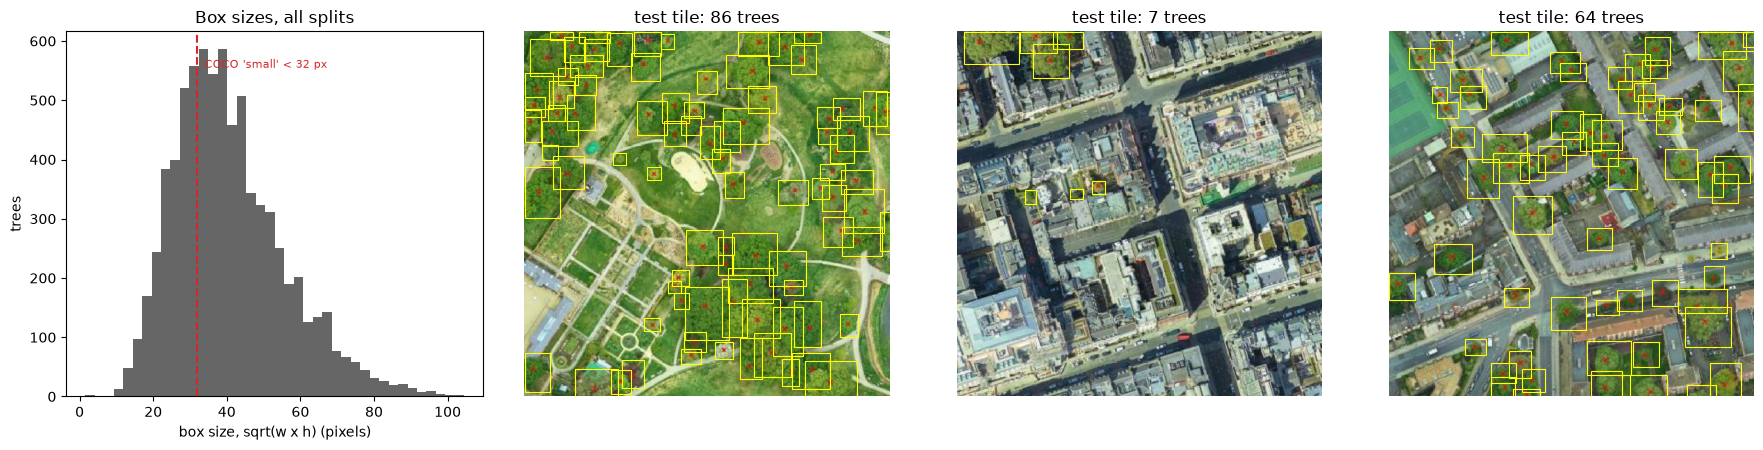

In [4]:
# The annotated tree dataset used in 09_10_01 (Roboflow, CC BY 4.0): 640 x 640 aerial tiles with YOLO boxes.
TREE = DATA / "Tree_Detection"

def yolo_boxes(label_file, size=640):
    """YOLO text labels (class, x-centre, y-centre, width, height; all 0-1) -> pixel boxes x0, y0, x1, y1."""
    a = np.loadtxt(label_file, ndmin=2)            # one row per box; ndmin=2 keeps a single box 2-D
    if a.size == 0:                                # an image without trees has an empty label file
        return np.zeros((0, 4))
    cx, cy, w, h = (a[:, 1:] * size).T             # drop the class column, fractions -> pixels
    return np.c_[cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2]   # centre + size -> corners

# One table row per tree box, with its split, image and size in pixels.
rows = []
for split in ("train", "valid", "test"):
    for img in sorted((TREE / split / "images").glob("*")):
        b = yolo_boxes(TREE / split / "labels" / f"{img.stem}.txt")   # the label file has the image's name
        for x0, y0, x1, y1 in b:
            rows.append({"split": split, "image": img.name, "width_px": x1 - x0, "height_px": y1 - y0})
trees = pd.DataFrame(rows)
# Per split: number of images and of trees, trees per image, and the median box size sqrt(w x h).
summary = trees.groupby("split").agg(images=("image", "nunique"), trees=("image", "size"))
summary["trees per image"] = (summary.trees / summary.images).round(1)
summary["median box (px)"] = trees.groupby("split").apply(lambda d: np.median(np.sqrt(d.width_px * d.height_px))).round(1)
display(summary.loc[["train", "valid", "test"]])

# Panel 1: histogram of box sizes; panels 2-4: three test tiles with their boxes.
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
size = np.sqrt(trees.width_px * trees.height_px)     # one size per box: the side of a square of equal area
ax[0].hist(size, bins=40, color="0.4"); ax[0].set_xlabel("box size, sqrt(w x h) (pixels)"); ax[0].set_ylabel("trees")
# COCO calls objects smaller than 32 x 32 px "small": mark that limit.
ax[0].axvline(32, color="C3", ls="--"); ax[0].text(34, ax[0].get_ylim()[1] * 0.9, "COCO 'small' < 32 px", color="C3", fontsize=8)
ax[0].set_title("Box sizes, all splits")
for a, img in zip(ax[1:], sorted((TREE / "test" / "images").glob("*"))[:3]):
    a.imshow(Image.open(img))                                            # the image tile
    for x0, y0, x1, y1 in yolo_boxes(TREE / "test" / "labels" / f"{img.stem}.txt"):
        a.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="yellow", lw=0.8))   # each tree box
    a.set_title(f"test tile: {len(yolo_boxes(TREE / 'test' / 'labels' / f'{img.stem}.txt'))} trees"); a.axis("off")
plt.tight_layout(); plt.show()

**What the tree dataset shows.**

- **Many objects.** 7,526 trees in 91 tiles, 82 to 85 per tile on average, but the count varies widely between tiles: from 7 trees in a dense city block to 86 in a park.
- **Small objects.** The median tree box is 32 to 42 px across, and a large share of the trees are COCO "small" objects (under 32 x 32 px). Small objects are the hardest case for detectors, because the backbone down-samples the image by 8 to 32 before the head sees it.
- **Touching objects.** Crowns touch and boxes overlap, so the NMS threshold decides whether two neighbouring trees stay separate.

09_10_01 trains a YOLO detector on the 64 training tiles and scores it with mAP on the 9 test tiles.

### Tiling a large image and merging duplicates

A detector reads a fixed input size, so a large scene is cut into overlapping windows. `detection_tiles` makes them at one or more scales: at scale 2 the window is half as large and is enlarged to the detector's input, so small objects cover twice as many pixels. Objects on a window edge are seen whole in the neighbouring window, and `merge_detections` removes the resulting duplicates in map units.


image 1920 x 939 px -> 40 windows: 8 of 640 px, 32 of 320 px


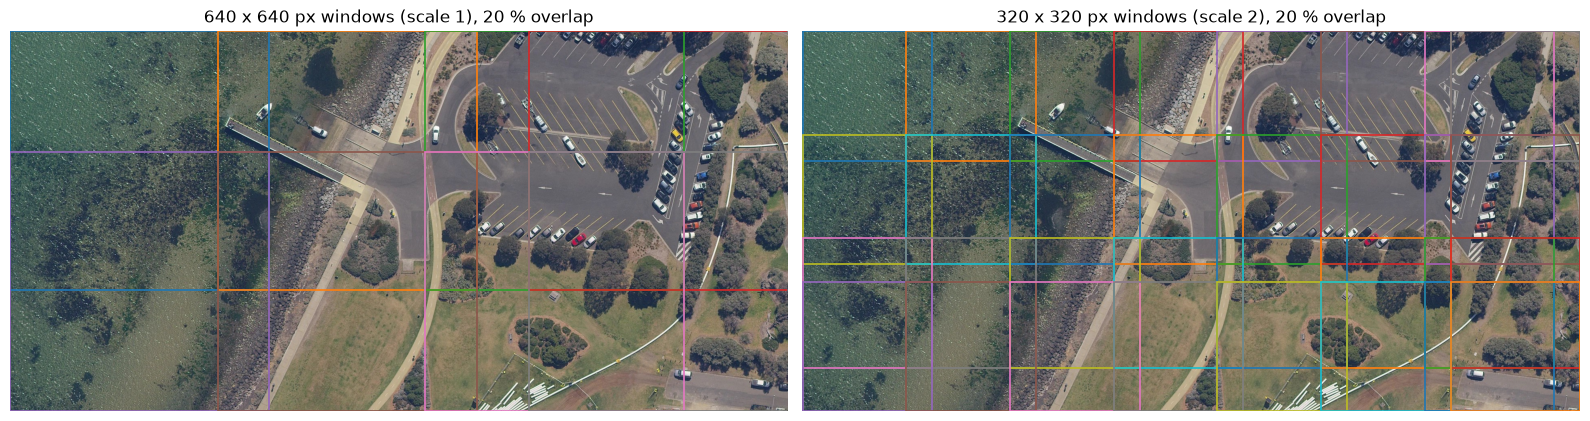

3 detections -> 2 after merge_detections


In [5]:
# A wide aerial image from the pool dataset, cut into overlapping detector windows at two scales.
pool = sorted((DATA / "cv2-pool-detection-master" / "data").glob("*.jpg"))[0]   # first image of the folder
im = np.asarray(Image.open(pool))              # image as an array of shape (rows, columns, 3)
H, W = im.shape[:2]                            # height and width in pixels
# Windows of 640 px (scale 1) and 320 px (scale 2), overlapping by 20 %; each is (row, col, size).
wins = ic.detection_tiles(H, W, tile=640, overlap=0.2, scales=(1.0, 2.0))
# Count the windows of each size.
print(f"image {W} x {H} px -> {len(wins)} windows: "
      + ", ".join(f"{sum(w[2] == s for w in wins)} of {s} px" for s in sorted({w[2] for w in wins}, reverse=True)))

# One panel per window size, each window drawn as a coloured square.
fig, ax = plt.subplots(1, 2, figsize=(16, 4.4))
for a, s in zip(ax, sorted({w[2] for w in wins}, reverse=True)):
    a.imshow(im)
    for k, (r, c, size) in enumerate(w for w in wins if w[2] == s):
        a.add_patch(Rectangle((c, r), size, size, fill=False, ec=f"C{k % 10}", lw=1.2))   # x = column, y = row
    a.set_title(f"{s} x {s} px windows (scale {640 / s:g}), 20 % overlap"); a.axis("off")
plt.tight_layout(); plt.show()

# Duplicates across tiles are merged in map units: one pool seen by two overlapping windows.
# Three detections as polygons: the first two are the same pool, the third is a different one.
dets = gpd.GeoDataFrame({"label": ["pool", "pool", "pool"], "score": [0.88, 0.71, 0.93]},
                        geometry=[box(500, 300, 540, 330), box(503, 301, 543, 332), box(1200, 600, 1235, 640)])
# merge_detections keeps the highest-scoring polygon of each overlapping group (polygon NMS).
print(f"{len(dets)} detections -> {len(ic.merge_detections(dets, iou_threshold=0.5))} after merge_detections")

**Windows.** The 1920 x 939 px image needs 8 windows of 640 px, and 32 windows of 320 px at scale 2. Halving the window quadruples the number of windows and the inference time, in exchange for doubling the pixels per object.

**Merging.** The 20 % overlap means an object near an edge appears in two windows. The two overlapping pool detections are merged into one and the separate one is kept: 3 detections become 2.

### From edges to field instances

Fields are found through their boundaries. Here the Sobel edge strength of the WorldView scene used in 09_10_03 is thresholded, and `boundary_to_instances` labels the closed regions, at a low and at a high threshold.


760 x 702 pixels of 1.6 m | digitised fields: 567, median 705 m²


,regions,median region (m²),largest region (% of scene)
threshold,,,
0.08,1121,58.9,4.3
0.25,449,66.6,39.5


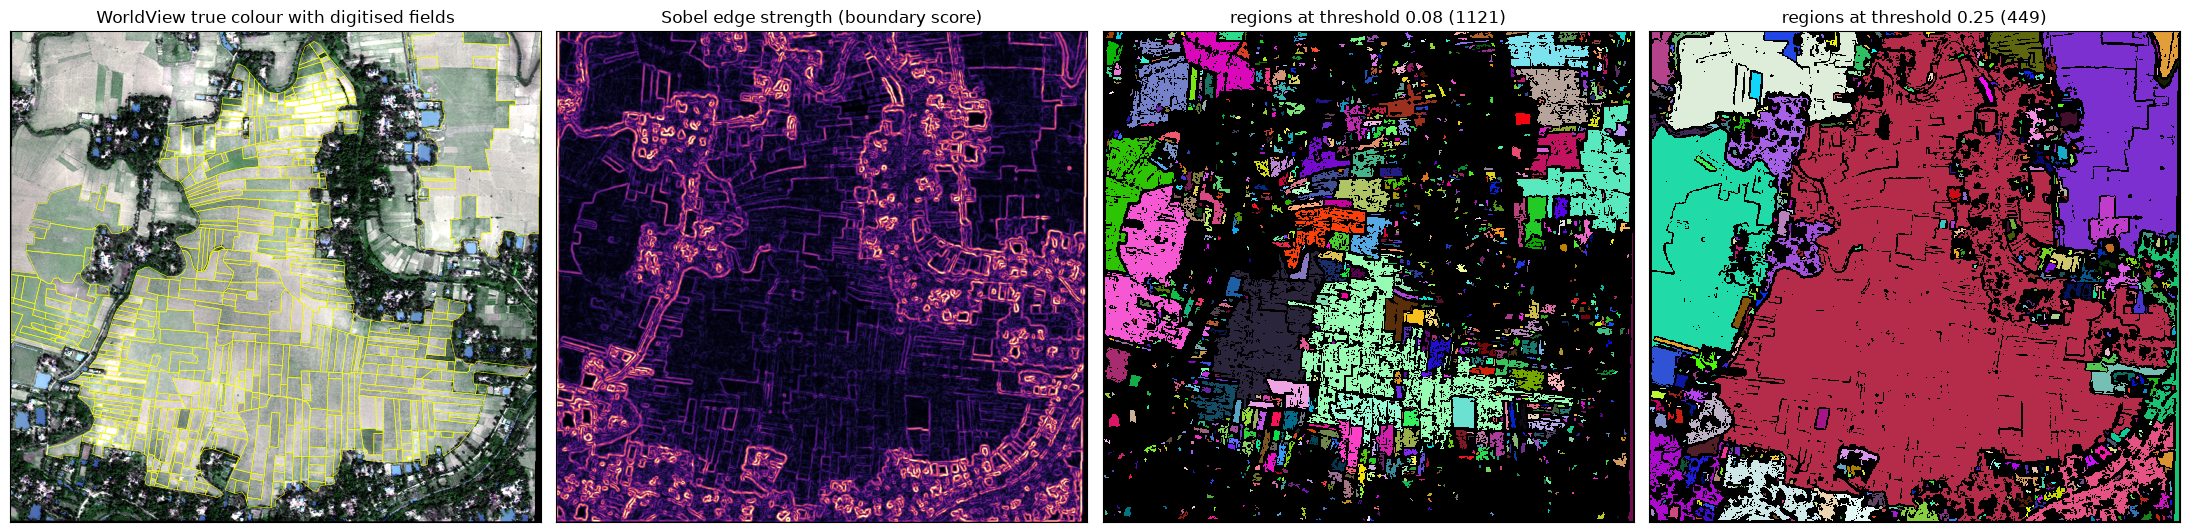

In [6]:
# Fields as objects: edges -> closed regions -> field instances, on the WorldView scene used in 09_10_03.
WV = DATA / "Edge_Detection" / "BD_WorldView"
with rasterio.open(WV / "multi.tif") as src:
    x = src.read([2, 3, 5]).astype("float32")              # blue, green, red
    T, CRS = src.transform, src.crs                        # georeference: affine transform and CRS
x[x <= -1e30] = np.nan                                     # the file's no-data value (-3.4e38) -> NaN
x[x == 65535] = np.nan                                     # saturated fill values -> NaN
rgb = np.moveaxis(x[::-1], 0, -1)                         # red, green, blue
# Digitised fields; the shapefile has no .prj, so the raster's CRS is assigned.
fields = gpd.read_file(WV / "aoi_trianing.shp").set_crs(CRS, allow_override=True)

# Sobel gradient magnitude of R, G and B (strongest band response), scaled to [0, 1].
edges = ed.classical_edges(np.nan_to_num(rgb), "sobel", sigma=1.0)
px_m2 = abs(T.a * T.e)                                     # area of one pixel in m² (1.6 m x 1.6 m)
INST, rows = {}, []
for th in (0.08, 0.25):                                   # a low and a high threshold on the edge score
    # Pixels with edge score >= th are boundary; the connected regions in between get one ID each.
    inst = INST[th] = ed.boundary_to_instances(edges, threshold=th, min_area_pixels=10, dilate_pixels=0)
    sizes = np.bincount(inst.ravel())[1:] * px_m2          # pixels per region ID (0 = boundary dropped) -> m²
    rows.append({"threshold": th, "regions": int(inst.max()), "median region (m²)": np.median(sizes),
                 "largest region (% of scene)": 100 * sizes.max() / (inst.size * px_m2)})
print(f"{src.width} x {src.height} pixels of {src.res[0]:g} m | digitised fields: {len(fields)}, "
      f"median {fields.area.median():.0f} m²")
display(pd.DataFrame(rows).set_index("threshold").round(1))

# A 2-98 % stretch of the RGB image for display.
show = np.clip((rgb - np.nanpercentile(rgb, 2, (0, 1))) / (np.nanpercentile(rgb, 98, (0, 1)) - np.nanpercentile(rgb, 2, (0, 1))), 0, 1)
ext = (T.c, T.c + src.width * T.a, T.f + src.height * T.e, T.f)   # left, right, bottom, top in map units
rng = np.random.default_rng(0)                                    # fixed seed: the same random colours every run
fig, ax = plt.subplots(1, 4, figsize=(22, 5.8))
ax[0].imshow(np.nan_to_num(show), extent=ext); fields.boundary.plot(ax=ax[0], color="yellow", lw=0.4)
ax[0].set_title("WorldView true colour with digitised fields")
ax[1].imshow(edges, cmap="magma", extent=ext); ax[1].set_title("Sobel edge strength (boundary score)")
for a, th in zip(ax[2:], INST):
    lut = np.vstack([[0, 0, 0], rng.random((INST[th].max(), 3))])   # colour table: black for 0, random per region
    a.imshow(lut[INST[th]], extent=ext, interpolation="nearest")    # look up each pixel's region colour
    a.set_title(f"regions at threshold {th} ({INST[th].max()})")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Two failure modes of a single threshold.** The 567 digitised fields have a median area of 705 m² (about 275 pixels).

- **Threshold 0.08: over-segmentation.** Texture inside fields, tree crowns and houses all count as boundary. The scene breaks into 1,121 fragments with a median of 59 m².
- **Threshold 0.25: under-segmentation.** The faint bunds inside the cropland fall below the threshold. One gap is enough to join two fields, so 39.5 % of the scene becomes a single region.

Neither result resembles the digitised fields. A brightness gradient cannot tell a bund from any other edge. That is the reason for learning the boundary with a network (09_10_02, 09_10_03) or using a pretrained field model (09_10_04). The conversion to instances, and its sensitivity to the threshold, stays the same.

### The models, built in one call

The detectors are built without pretrained weights (`pretrained=False`), so nothing is downloaded. In evaluation mode a torchvision detector takes a list of images and returns, for each, a dictionary of boxes, labels and scores (and masks for Mask R-CNN). The boundary networks return two logits per pixel.


In [7]:
import torch

# Detectors and boundary networks are built with one call; no weights are downloaded here.
rows = []
x = torch.rand(3, 256, 256)                    # one random 3-band image of 256 x 256 pixels
for arch in ("faster_rcnn", "retinanet", "fcos", "mask_rcnn"):
    try:
        # pretrained=False: random weights, so nothing is downloaded; 2 classes = background + object.
        m = ic.build_object_detector(arch, num_classes=2, pretrained=False).eval()
        with torch.no_grad():                  # inference only: no gradients
            out = m([x])[0]                    # torchvision detectors take a list of images, return a list of dicts
        rows.append({"family": "object detector", "model": arch, "parameters (M)": round(ic.count_parameters(m) / 1e6, 1),
                     "output for one 3 x 256 x 256 image": ", ".join(f"{k} {tuple(v.shape)}" for k, v in out.items())})
    except Exception as e:                     # record the error instead of stopping the notebook
        rows.append({"family": "object detector", "model": arch, "parameters (M)": None,
                     "output for one 3 x 256 x 256 image": f"{type(e).__name__}: {e}"[:80]})
for arch, kw in (("unet_basic", {"base": 32}), ("FC-DenseNet56", {}), ("FCN-DKConv6", {}), ("SegNet", {})):
    m = ed.build_edge_model(arch, in_channels=3, device="cpu", **kw).eval()   # a 3-channel boundary network
    with torch.no_grad():
        out = m(x[None])                       # x[None] adds the batch dimension: (1, 3, 256, 256)
    rows.append({"family": "boundary network", "model": arch, "parameters (M)": round(ic.count_parameters(m) / 1e6, 2),
                 "output for one 3 x 256 x 256 image": f"logits {tuple(out.shape)}"})
display(pd.DataFrame(rows).set_index(["family", "model"]))

parameters (M)  \
family           model                           
object detector  faster_rcnn             43.30   
                 retinanet               36.40   
                 fcos                    32.10   
                 mask_rcnn               45.90   
boundary network unet_basic               7.76   
                 FC-DenseNet56            1.38   
                 FCN-DKConv6              0.12   
                 SegNet                  29.47   

                                               output for one 3 x 256 x 256 image  
family           model                                                             
object detector  faster_rcnn         boxes (100, 4), labels (100,), scores (100,)  
                 retinanet                 boxes (0, 4), scores (0,), labels (0,)  
                 fcos                      boxes (0, 4), scores (0,), labels (0,)  
                 mask_rcnn      boxes (100, 4), labels (100,), scores (100,), ...  
boundary network unet_basic                               logits (1, 2, 256, 256)  
                 FC-DenseNet56                            logits (1, 2, 256, 256)  
                 FCN-DKConv6                              logits (1, 2, 256, 256)  
                 SegNet                                   logits (1, 2, 256, 256)

**Sizes.** The detectors have 32 to 46 million parameters. The boundary networks range from 0.12 million (FCN-DKConv6) to 29.5 million (SegNet).

**Outputs here.** The weights are random, so the outputs show only the format. RetinaNet and FCOS return no box above their score threshold, and Faster R-CNN and Mask R-CNN return their maximum of 100 boxes. Training (09_10_01, 09_10_02, 09_10_03) or pretrained weights (09_10_04) make them meaningful.

The pretrained Fields of The World models available through `ed.load_ftw_model` (used in 09_10_04):


In [8]:
# Pretrained field-boundary models that GeoLattice can load (checkpoints are downloaded only on request).
# ed.ftw_models() returns one row per Fields of The World checkpoint; show version, licence and description.
display(ed.ftw_models()[["version", "license", "description"]])

,version,license,description
model,,,
FTW_PRUE_EFNET_B3,v3,Mixed Open Licenses (incl. CC-BY-NC-SA),"3-class, EfficientNet-B3: fastest"
FTW_PRUE_EFNET_B5,v3,Mixed Open Licenses (incl. CC-BY-NC-SA),"3-class, EfficientNet-B5: FTW default"
FTW_PRUE_EFNET_B7,v3,Mixed Open Licenses (incl. CC-BY-NC-SA),"3-class, EfficientNet-B7: most accurate"
FTW_PRUE_EFNET_B3_CCBY,v3.1,CC-BY-4.0,"3-class, B3, CC-BY/CC0 training data only"
FTW_PRUE_EFNET_B5_CCBY,v3.1,CC-BY-4.0,"3-class, B5, CC-BY/CC0 training data only"
FTW_PRUE_EFNET_B7_CCBY,v3.1,CC-BY-4.0,"3-class, B7, CC-BY/CC0 training data only"
FTW_v2_3_Class_FULL_multiWindow,v2,Mixed Open Licenses (incl. CC-BY-NC-SA),"legacy 3-class, two windows"
FTW_v1_3_Class_FULL,v1,Mixed Open Licenses (incl. CC-BY-NC-SA),legacy 3-class
FTW_v1_3_Class_CCBY,v1,CC-BY-4.0,"legacy 3-class, CC-BY data only"


Check the licence column before using a model: the standard FTW v3 models were trained partly on CC-BY-NC-SA data, while the `_CCBY` variants use only CC-BY/CC0 data. Delineate Anything is AGPL-3.

## Choosing a method

| Your situation | Start with | Then consider |
|---|---|---|
| Distinct objects (trees, pools, vehicles), a few hundred labelled boxes | YOLO (`build_object_detector("yolo")`) fine-tuned from pretrained weights | Faster R-CNN for small objects; scale-2 windows |
| Objects at arbitrary rotation (ships, buildings) | YOLO-OBB weights | `polygon_iou` for evaluation |
| A colour or shape rule clearly separates the objects, no labels yet | a classical rule (HSV threshold, contours) as in 09_10_01 | label boxes, then a learned detector |
| You need object outlines, not boxes | Mask R-CNN | `instances_from_detector`, `export_vectors` |
| Fields in very-high-resolution images (< 1 m), labelled outlines available | FC-DenseNet or U-Net via `build_edge_model` | classical baseline, tolerance scoring |
| Fields in very-high-resolution images, no labels | Delineate Anything, SAM 2.1 | fine-tune Delineate Anything on a few tiles |
| Fields from Sentinel-2 (10 m), anywhere | FTW B5 / B5_CCBY with crop-calendar windows | Delineate Anything on an RGB composite; `to_fiboa` |
| A new region | a few local labelled tiles plus a pretrained model | an independent test site |


## The notebooks in this chapter

| Notebook | Question | Data | Methods |
|---|---|---|---|
| **09_10_01** Object detection | Where are the swimming pools, and how many trees are in each tile? | `cv2-pool-detection-master` (29 aerial images, no labels); `Tree_Detection` (91 labelled tiles) | HSV/contour proposals, NMS, overlapping windows, detector mathematics, YOLO trained and tested on trees, mAP |
| **09_10_02** Field edges, Google screenshots | Can field boundaries be found in free Google imagery of Bangladesh? | `Edge_Detection/BD_Google_Screenshot` (60 labelled tiles) | classical edges, FC-DenseNet56/67/103, Delineate Anything V2 (pretrained and fine-tuned), SAM 2.1, field polygons |
| **09_10_03** Field edges, WorldView | Does NIR help, and which of six networks is best? (replication of Yang et al. 2020) | `Edge_Detection/BD_WorldView` (WorldView, 567 fields) | rasterised boundaries, block split, classical edges, texture random forest, U-Net, SegNet, FC-DenseNet56/67/103, FCN-DKConv6, ROC, tolerance |
| **09_10_04** Field edges, Sentinel-2 | Do pretrained global models map US Corn Belt fields from free 10 m imagery? | `Corn_belt` (Sentinel-2 and CDL, 2024 to 2025) | Fields of The World B3/B5/B7, Delineate Anything, classical edges, settings chosen on 2024 and tested on 2025, fiboa export |

The capstone `09_13_Capstones/09_13_14_field_edge_detection_across_four_countries_training_in_mexico_mali_cambodia_and_bangladesh_testing_on_an_unseen_bangladesh_site.ipynb` uses the same methods, training in Mexico, Mali, Cambodia and Bangladesh and testing on a second Bangladesh site.


## Summary, exercises and references

### Summary

- **Objects instead of classes.** Object detection returns a set of objects with boxes, classes and scores. Fields, which touch and fill the landscape, are found through their boundaries instead: predict the boundary, then label the closed regions.
- **IoU is the shared geometry.** It drives NMS, the matching of detections to the truth, and the matching of field polygons.
- **mAP depends on the IoU threshold.** AP@0.50, AP@0.75 and COCO AP@[.50:.95] reward increasingly precise localisation, so always state the threshold.
- **Overhead imagery needs adapting.** Small, dense, rotated objects in huge georeferenced scenes call for tiling, scale-aware windows, rotation augmentation, duplicate merging in map units, and spatial or site-level hold-outs.
- **One threshold decides field instances.** In boundary-to-instance conversion it trades over-segmentation against merged fields, so choose it by object matching on validation data.
- **GeoLattice covers the whole path.** `ic` handles boxes and `ed` handles field boundaries, from labels and training to polygons, metrics and fiboa output.

### Exercises

1. In the IoU and NMS example, change the NMS threshold to 0.3 and 0.75. Which boxes survive, and what happens to two real trees that touch?
2. In the average precision example, shift box A by 4, 8 and 12 pixels. At which shift does it stop counting at AP@0.75, and at AP@0.50?
3. In the tree dataset, how many of the test-tile trees are COCO "small" objects (< 32 x 32 px)? What would happen to them if the tiles were down-sampled to 320 px?
4. In the tiling example, add `scales=(1.0, 2.0, 4.0)`. How many windows does the image need, and how many times is each pixel predicted?
5. In the edges-to-instances example, try thresholds from 0.05 to 0.3 and `dilate_pixels=1`. Plot the number of regions and the size of the largest region against the threshold. Which setting comes closest to the 567 digitised fields, and do its regions look like fields?
6. Run `ed.classical_edges` with `"canny"` and `"log"` on the same scene. Which gives cleaner closed regions?

### References

- Carion, N. et al. (2020). End-to-end object detection with transformers (DETR). *ECCV*.
- Everingham, M. et al. (2010). The PASCAL visual object classes (VOC) challenge. *IJCV*, 88, 303-338.
- He, K., Gkioxari, G., Dollár, P., Girshick, R. (2017). Mask R-CNN. *ICCV*.
- Jégou, S. et al. (2017). The one hundred layers tiramisu: fully convolutional DenseNets for semantic segmentation. *CVPR Workshops*.
- Kerner, H. et al. (2025). Fields of The World: a machine learning benchmark dataset for global agricultural field boundary segmentation. *AAAI*.
- Lavreniuk, M. et al. (2025). Delineate Anything: resolution-agnostic field boundary delineation on satellite imagery. *arXiv:2504.02534*.
- Lin, T.-Y. et al. (2014). Microsoft COCO: common objects in context. *ECCV*.
- Lin, T.-Y., Goyal, P., Girshick, R., He, K., Dollár, P. (2017). Focal loss for dense object detection (RetinaNet). *ICCV*.
- Redmon, J., Divvala, S., Girshick, R., Farhadi, A. (2016). You only look once: unified, real-time object detection. *CVPR*.
- Ren, S., He, K., Girshick, R., Sun, J. (2015). Faster R-CNN: towards real-time object detection with region proposal networks. *NeurIPS*.
- Tian, Z., Shen, C., Chen, H., He, T. (2019). FCOS: fully convolutional one-stage object detection. *ICCV*.
- Xia, G.-S. et al. (2018). DOTA: a large-scale dataset for object detection in aerial images. *CVPR*.
- Yang, R., Ahmed, Z. U., Schulthess, U. C., Kamal, M., Rai, R. (2020). Detecting functional field units from satellite images in smallholder farming systems using a deep learning based computer vision approach: a case study from Bangladesh. *Remote Sensing Applications: Society and Environment*, 20, 100413.
